<p class="lead">Deep learning has transformed parts of this laboratory's work and left other parts untouched. Structure prediction, protein language models and generative chemistry are now unthinkable without it; small tabular structure-activity datasets of a few thousand compounds are still, more often than not, best served by gradient boosting. This unit teaches the essentials from the mathematics up — the multilayer perceptron, the forward pass, backpropagation derived and then verified by hand against PyTorch's autograd, stochastic gradient descent, and the three regularisers you will actually use — and then runs the comparison that matters: <strong>the same scaffold split, a neural network and a gradient-boosting model, with the same preprocessing and an honestly tuned learning rate</strong>. The second half explains what a pretrained molecular or protein representation is, how frozen embeddings are used as features, and — because no pretrained weights can be downloaded in this course's offline environment — substitutes a transparent surrogate trained in the notebook, clearly labelled as such.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad presenta los fundamentos del aprendizaje profundo ejecutable en CPU. Se desarrolla el perceptrón multicapa, el paso hacia adelante y la retropropagación, con un ejemplo numérico resuelto a mano y verificado contra la diferenciación automática de PyTorch; luego el descenso de gradiente estocástico (Adam/AdamW) y la regularización mediante dropout, decaimiento de pesos y detención temprana. Se entrena una red pequeña sobre huellas moleculares de Morgan del conjunto ROCK1 con partición por andamiaje de Bemis-Murcko y se compara honestamente con un modelo de potenciación de gradiente, incluyendo una búsqueda de hiperparámetros sobre el conjunto de validación y curvas de aprendizaje frente al tamaño del entrenamiento. Finalmente se explica qué son las representaciones preentrenadas (modelos de lenguaje químico tipo ChemBERTa y modelos de proteínas como ESM-2) y cómo se usan sus incrustaciones congeladas como variables; como no es posible descargar pesos preentrenados en este entorno sin red, se utiliza un sustituto transparente (autocodificador y SVD de las huellas entrenados en la propia libreta), declarado explícitamente como sustituto y no como modelo preentrenado.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Explain the multilayer perceptron, backpropagation, stochastic gradient descent, regularisation (dropout, weight decay, early stopping) and the role of the validation set.</li>
<li>Train a small network in PyTorch on molecular data with a correct training loop and reproducible seeds, and compare it honestly with gradient boosting under the same split.</li>
<li>Explain what pretrained molecular (ChemBERTa-type) and protein (ESM-2) embeddings are, how frozen embeddings are used in a classical pipeline, and when transfer learning helps.</li>
<li>Read a deep-learning paper's methods critically: data splits, baselines, compute and released code.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Everything here runs on a CPU in a few minutes; there is no GPU anywhere in this course. In Colab run <code>!pip install rdkit lightgbm</code> once before the setup cell (PyTorch is pre-installed there). Read <a href="../U11_Supervised_Workflow/index.html">Unit 11</a> and <a href="../U12_Validation/index.html">Unit 12</a> first — the split and the baseline used here come from them — and <a href="../U14_Ensembles_Tuning/index.html">Unit 14</a> for the gradient-boosting competitor. This unit is <em>extended</em> material: skip it on a first pass if your project is a classical QSAR or a simulation analysis, and read it before you referee or write a paper that uses a neural network.</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit lightgbm   (PyTorch is already installed there)
from pathlib import Path
import urllib.request, time, math, itertools, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, rdkit, torch, torch.nn as nn, lightgbm as lgb
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(4)                       # keep the build reproducible and polite on a shared machine
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("torch", torch.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| lightgbm", lgb.__version__, "| rdkit", rdkit.__version__)
print("CUDA available:", torch.cuda.is_available(), "| threads", torch.get_num_threads())

torch 2.13.0 | numpy 2.4.6 | scikit-learn 1.9.0 | lightgbm 4.6.0 | rdkit 2026.03.4
CUDA available: False | threads 4


In [2]:
# Data: the ROCK1 table, Morgan fingerprints, and a three-way scaffold split (train / validation / test).
df = load_data("rock1_chembl_curated.csv")
cmp_ = df.loc[~df["censored"]].reset_index(drop=True)
y = cmp_["pActivity"].to_numpy(dtype=np.float32)
ycls = (y >= 7.0).astype(int)
scaf = cmp_["scaffold_smiles"].to_numpy()
mols = [Chem.MolFromSmiles(s) for s in cmp_["std_smiles"]]
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
Xfp = np.array([gen.GetFingerprintAsNumPy(m) for m in mols], dtype=np.float32)

def scaffold_split(scaffolds, fr=(0.70, 0.15)):
    '''Deterministic Bemis-Murcko split: largest families to training, rarest to test.'''
    groups = pd.Series(scaffolds).groupby(scaffolds).groups
    order = sorted(groups.values(), key=lambda g: (-len(g), str(scaffolds[g[0]])))
    tr, va, te = [], [], []
    n1, n2 = int(fr[0] * len(scaffolds)), int(fr[1] * len(scaffolds))
    for g in order:
        (tr if len(tr) < n1 else va if len(va) < n2 else te).extend(list(g))
    return np.array(tr), np.array(va), np.array(te)

TRs, VAs, TEs = scaffold_split(scaf)
_p = np.random.default_rng(0).permutation(len(y))
TRr, VAr, TEr = _p[:int(.70*len(y))], _p[int(.70*len(y)):int(.85*len(y))], _p[int(.85*len(y)):]
print(f"compounds {len(y)}, features {Xfp.shape[1]} bits ({Xfp.sum(1).mean():.0f} set per molecule on average)")
print(f"scaffold split: train {len(TRs)} / val {len(VAs)} / test {len(TEs)}; "
      f"scaffolds shared between train and test {len(set(scaf[TRs]) & set(scaf[TEs]))}")
print(f"random split  : train {len(TRr)} / val {len(VAr)} / test {len(TEr)}")
print(f"target: mean {y.mean():.2f}, sd {y.std():.2f}; scaffold-test mean {y[TEs].mean():.2f} "
      f"(the rare-scaffold compounds are less potent on average)")

compounds 2764, features 2048 bits (52 set per molecule on average)
scaffold split: train 1934 / val 414 / test 416; scaffolds shared between train and test 0
random split  : train 1934 / val 415 / test 415
target: mean 6.51, sd 1.11; scaffold-test mean 6.10 (the rare-scaffold compounds are less potent on average)


## 1. Where deep learning changed the field, and where it did not

Three statements, each with evidence behind it.

**It changed structural biology.** AlphaFold2 turned protein-structure prediction from an open problem into a utility<sup class="c"><a href="#r27">[27]</a></sup>, and AlphaFold3 extended the same approach to complexes with ligands and nucleic acids<sup class="c"><a href="#r28">[28]</a></sup>. Protein language models trained on hundreds of millions of sequences predict structure directly from sequence and produce embeddings that carry functional information<sup class="c"><a href="#r25">[25]</a><a href="#r26">[26]</a></sup>.

**It changed representation learning for molecules.** Chemical language models trained on tens of millions of SMILES strings<sup class="c"><a href="#r22">[22]</a><a href="#r23">[23]</a></sup>, learned continuous descriptors from translation objectives<sup class="c"><a href="#r24">[24]</a></sup> and message-passing graph networks<sup class="c"><a href="#r18">[18]</a></sup> give molecular representations that need no hand-chosen descriptors.

**It did not change small tabular QSAR.** On datasets of the size this laboratory usually has — hundreds to a few thousand compounds, a single target, heterogeneous public measurements — gradient-boosted trees remain at least competitive, and often better, than neural networks. That is not an opinion: it is the conclusion of systematic comparisons on tabular data generally<sup class="c"><a href="#r14">[14]</a><a href="#r15">[15]</a></sup> and of the re-analysis of the largest published deep-learning-versus-classical comparison in cheminformatics, where the reported advantage of deep learning shrank substantially once the validation protocol was corrected<sup class="c"><a href="#r16">[16]</a><a href="#r17">[17]</a></sup>. Sections 5 to 7 reproduce that finding on our own data.

The practical consequence for a student joining the group: learn the mechanics well enough to use pretrained models and to referee papers that use them, and do not reach for a network when 2,000 rows and 2,048 sparse features are what you have.

<div class="box bridge"><h4>Domain context — what a neural network is being asked to do here</h4>
<p>Our input is a <strong>Morgan fingerprint</strong>: a 2,048-bit vector in which each bit records the presence of one circular atom environment of radius up to 2. It is sparse (about 50 bits set per molecule), binary, and its coordinates have no order or metric — bit 1,407 is not "between" bits 1,406 and 1,408. A network's first layer must therefore learn 2,048 independent weights per hidden unit from fewer than 2,000 training molecules, with no spatial or sequential structure to exploit, which is precisely the regime where the inductive biases that make deep learning powerful (locality, weight sharing, hierarchy) do not apply. The output is <strong>pActivity</strong>, the negative base-10 logarithm of the measured IC50/Ki/Kd in molar units, so 7.0 means 100 nM and an error of 1.0 is a tenfold error in potency. The measurements come from many papers and carry an experimental uncertainty of roughly half a log unit (<a href="../U17_Uncertainty_AD/index.html">Unit 17</a>), which caps what any architecture can achieve.</p></div>

## 2. The multilayer perceptron

A **multilayer perceptron** (MLP) composes affine maps with a non-linear activation. For one hidden layer,

$$ \mathbf{z}^{(1)} = \mathbf{W}^{(1)}\mathbf{x} + \mathbf{b}^{(1)}, \qquad
   \mathbf{a}^{(1)} = \phi\!\left(\mathbf{z}^{(1)}\right), \qquad
   \hat y = \mathbf{W}^{(2)}\mathbf{a}^{(1)} + b^{(2)} , $$

with $\phi$ applied elementwise. The activation is what makes the composition more than a single linear map: without it, stacking layers collapses to one matrix product. The standard choice is the rectified linear unit $\phi(z)=\max(0,z)$, whose derivative is the indicator $\mathbb{1}[z>0]$ — cheap, and free of the saturation that makes sigmoids train slowly<sup class="c"><a href="#r1">[1]</a></sup>.

For regression the loss is the mean squared error $L = \frac{1}{N}\sum_i (\hat y_i - y_i)^2$; for binary classification, the binary cross-entropy. Everything else — depth, width, dropout, weight decay — is a way of controlling how a model with more parameters than data points behaves<sup class="c"><a href="#r11">[11]</a></sup>. Our network below has about half a million parameters and 1,934 training compounds, a ratio of roughly 250 parameters per observation; classical statistics says this cannot work, and it does work, which is the phenomenon the field is still explaining.

parameters of the network used below: 541,056 for 1934 training compounds (280 per observation)


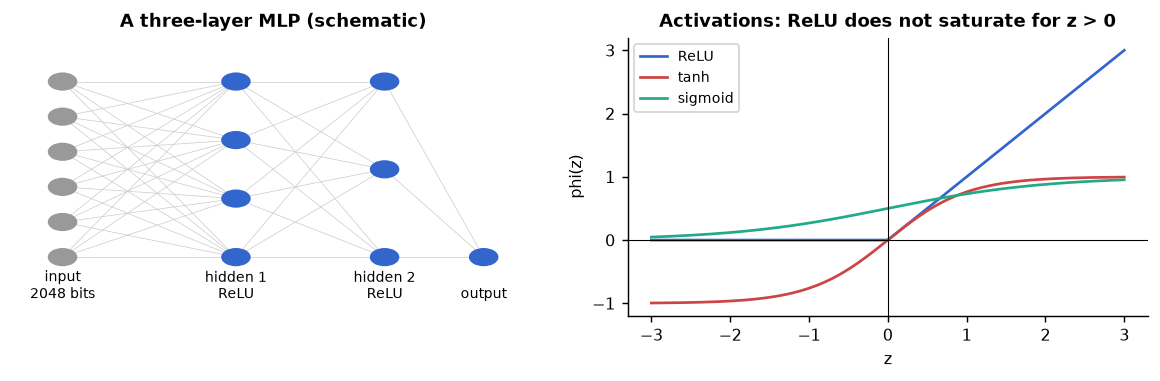

In [3]:
# Figure 1: the architecture and the activations, drawn with matplotlib.
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.0))
ax = axes[0]
layers = [(0.1, 6, "input\n2048 bits"), (0.45, 4, "hidden 1\nReLU"), (0.75, 3, "hidden 2\nReLU"), (0.95, 1, "output")]
pos = {}
for li, (x, n, lab) in enumerate(layers):
    ys = np.linspace(0.2, 0.8, n)
    pos[li] = [(x, yy) for yy in ys]
    for (xx, yy) in pos[li]:
        ax.add_patch(plt.Circle((xx, yy), 0.028, color="#36c" if li else "#999", zorder=3))
    ax.text(x, 0.06, lab, ha="center", fontsize=7.5)
for li in range(len(layers) - 1):
    for (x1, y1) in pos[li]:
        for (x2, y2) in pos[li + 1]:
            ax.plot([x1, x2], [y1, y2], color="#ccc", lw=.4, zorder=1)
ax.set_xlim(0, 1.05); ax.set_ylim(0, 0.95); ax.axis("off")
ax.set_title("A three-layer MLP (schematic)")
z = np.linspace(-3, 3, 200)
for name, f, colr in [("ReLU", np.maximum(0, z), "#36c"), ("tanh", np.tanh(z), "#c44"),
                      ("sigmoid", 1/(1+np.exp(-z)), "#2a8")]:
    axes[1].plot(z, f, label=name, color=colr)
axes[1].axhline(0, color="k", lw=.6); axes[1].axvline(0, color="k", lw=.6)
axes[1].set_xlabel("z"); axes[1].set_ylabel("phi(z)"); axes[1].legend(fontsize=7.5)
axes[1].set_title("Activations: ReLU does not saturate for z > 0")
fig.tight_layout()
n_params = 2048*256 + 256 + 256*64 + 64 + 64
print(f"parameters of the network used below: {n_params:,} for {len(TRs)} training compounds "
      f"({n_params/len(TRs):.0f} per observation)")

<p class="caption"><b>Figure 1.</b> Left: the architecture used in this unit, schematically — a fully connected network from the fingerprint to a scalar prediction. Right: three activation functions; ReLU is piecewise linear and has constant gradient for positive inputs, while tanh and the sigmoid flatten at both ends, which slows learning when units saturate.</p>

## 3. Backpropagation, derived and checked by hand

Training means computing $\partial L/\partial \theta$ for every parameter. Backpropagation is the chain rule applied in reverse order, reusing intermediate results. For the two-layer network above with a squared-error loss on one example,

$$ \frac{\partial L}{\partial \hat y} = (\hat y - y), \qquad
   \frac{\partial L}{\partial \mathbf{W}^{(2)}} = (\hat y - y)\,\mathbf{a}^{(1)\top}, \qquad
   \frac{\partial L}{\partial b^{(2)}} = (\hat y - y), $$

$$ \boldsymbol{\delta}^{(1)} = \left(\mathbf{W}^{(2)\top}(\hat y - y)\right) \odot \phi'\!\left(\mathbf{z}^{(1)}\right), \qquad
   \frac{\partial L}{\partial \mathbf{W}^{(1)}} = \boldsymbol{\delta}^{(1)}\mathbf{x}^{\top}, \qquad
   \frac{\partial L}{\partial \mathbf{b}^{(1)}} = \boldsymbol{\delta}^{(1)} . $$

Two facts are worth internalising. The cost of the backward pass is the same order as the forward pass, which is why training a network is feasible at all<sup class="c"><a href="#r2">[2]</a></sup>. And the only place the loss enters is through $(\hat y - y)$: everything else is the network's own geometry.

### 3.1 Worked example by hand

Take $\mathbf{x} = (1, 2)$, $y = 1$, and

$$\mathbf{W}^{(1)} = \begin{pmatrix} 0.10 & -0.20 \\ 0.30 & 0.40\end{pmatrix},\quad
\mathbf{b}^{(1)} = (0.05,\, -0.05),\quad
\mathbf{W}^{(2)} = (0.50,\, -0.60)^{\top},\quad b^{(2)} = 0.10,$$

with the convention $\mathbf{z}^{(1)} = \mathbf{x}\mathbf{W}^{(1)} + \mathbf{b}^{(1)}$ (row-vector form, as in PyTorch) and $L = \tfrac12(\hat y - y)^2$.

| step | computation | value |
|---|---|---|
| $z^{(1)}_1$ | $1(0.10) + 2(0.30) + 0.05$ | $0.75$ |
| $z^{(1)}_2$ | $1(-0.20) + 2(0.40) - 0.05$ | $0.55$ |
| $a^{(1)}$ | $\max(0, z)$ | $(0.75,\ 0.55)$ |
| $\hat y$ | $0.75(0.50) + 0.55(-0.60) + 0.10$ | $0.145$ |
| $L$ | $\tfrac12(0.145-1)^2$ | $0.3655$ |
| $\partial L/\partial \hat y$ | $0.145 - 1$ | $-0.855$ |
| $\partial L/\partial W^{(2)}$ | $-0.855 \times (0.75, 0.55)$ | $(-0.6413,\ -0.4703)$ |
| $\delta^{(1)}$ | $-0.855 \times (0.50, -0.60) \odot (1, 1)$ | $(-0.4275,\ +0.513)$ |
| $\partial L/\partial W^{(1)}$ | $(1,2)^{\top}\,\delta^{(1)}$ | $\begin{pmatrix}-0.4275 & 0.513\\ -0.855 & 1.026\end{pmatrix}$ |

Both ReLU units are active, so $\phi'(z) = 1$ for both and the gradient passes through unchanged. The next cell asks PyTorch's autograd for the same numbers.

In [4]:
# The hand calculation, verified by autograd.
W1 = torch.tensor([[0.10, -0.20], [0.30, 0.40]], requires_grad=True)
b1 = torch.tensor([0.05, -0.05], requires_grad=True)
W2 = torch.tensor([[0.50], [-0.60]], requires_grad=True)
b2 = torch.tensor([0.10], requires_grad=True)
x1 = torch.tensor([[1.0, 2.0]]); y1 = torch.tensor([[1.0]])
z1 = x1 @ W1 + b1
a1 = torch.relu(z1)
yhat = a1 @ W2 + b2
loss = 0.5 * (yhat - y1) ** 2
loss.backward()
print(f"forward : z1 = {z1.detach().numpy().ravel().round(4)}  a1 = {a1.detach().numpy().ravel().round(4)}  "
      f"yhat = {yhat.item():.4f}  L = {loss.item():.4f}")
print(f"backward: dL/dW2 = {W2.grad.numpy().ravel().round(4)}   dL/db2 = {b2.grad.numpy().round(4)}")
print(f"          dL/dW1 =\n{W1.grad.numpy().round(4)}")
print(f"          dL/db1 = {b1.grad.numpy().round(4)}  (= delta^(1), as derived)")
hand = {"yhat": 0.145, "L": 0.3655, "dW2": [-0.6413, -0.4703], "db1": [-0.4275, 0.5130]}
print(f"\nagreement with the hand calculation: yhat {abs(yhat.item()-hand['yhat']):.1e}, "
      f"L {abs(loss.item()-hand['L']):.1e}, "
      f"dW2 {np.abs(W2.grad.numpy().ravel()-np.array(hand['dW2'])).max():.1e}, "
      f"db1 {np.abs(b1.grad.numpy()-np.array(hand['db1'])).max():.1e}")

forward : z1 = [0.75 0.55]  a1 = [0.75 0.55]  yhat = 0.1450  L = 0.3655
backward: dL/dW2 = [-0.6413 -0.4702]   dL/db2 = [-0.855]
          dL/dW1 =
[[-0.4275  0.513 ]
 [-0.855   1.026 ]]
          dL/db1 = [-0.4275  0.513 ]  (= delta^(1), as derived)

agreement with the hand calculation: yhat 1.1e-08, L 1.3e-05, dW2 5.0e-05, db1 1.1e-08


Autograd reproduces the hand calculation to four decimals, which is the point of doing it once: `loss.backward()` is not magic, it is the table above executed in reverse.

## 4. Stochastic gradient descent and the training loop

Full-batch gradient descent computes the gradient on all $N$ examples per step; **stochastic** gradient descent<sup class="c"><a href="#r3">[3]</a><a href="#r4">[4]</a></sup> uses a mini-batch, trading gradient accuracy for many more steps per unit of computation, and the resulting noise helps escape poor regions. The update $\theta \leftarrow \theta - \eta\, \nabla_\theta L$ needs a step size $\eta$; **Adam**<sup class="c"><a href="#r5">[5]</a></sup> adapts it per parameter from running estimates of the gradient's first and second moments, and **AdamW**<sup class="c"><a href="#r6">[6]</a></sup> fixes its interaction with weight decay by applying the decay directly to the weights rather than through the gradient. AdamW with $\eta \in [10^{-4}, 10^{-3}]$ is the default worth starting from.

PyTorch<sup class="c"><a href="#r12">[12]</a><a href="#r13">[13]</a></sup> supplies the three pieces this needs: tensors with automatic differentiation, `nn.Module` containers and optimisers. Two further details are defaults here but worth knowing — **initialisation**, which draws weights from a scale that keeps activations from vanishing or exploding across layers<sup class="c"><a href="#r9">[9]</a></sup> (Section 5.1 shows what an all-zeros initialisation does), and **batch normalisation**<sup class="c"><a href="#r10">[10]</a></sup>, which standardises activations inside the network and is usually unnecessary in a two-layer model on standardised inputs.

A correct training loop has five elements, all visible in the function below: a seed, mini-batch shuffling, `opt.zero_grad()` before each backward pass, evaluation in `eval()` mode with `torch.no_grad()` (so dropout is switched off), and **early stopping on a validation set with restoration of the best weights**<sup class="c"><a href="#r8">[8]</a></sup>. Forgetting `zero_grad` accumulates gradients across batches; forgetting `eval()` reports a validation loss contaminated by dropout noise; forgetting to restore the best weights returns the overfitted final model instead of the best one.

In [5]:
# A complete, reusable training loop (PyTorch on CPU).
def make_mlp(n_in, hidden=256, hidden2=64, dropout=0.3, seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(n_in, hidden), nn.ReLU(), nn.Dropout(dropout),
                         nn.Linear(hidden, hidden2), nn.ReLU(), nn.Dropout(dropout),
                         nn.Linear(hidden2, 1))

def train_mlp(X, tr, va, hidden=256, dropout=0.3, lr=1e-3, weight_decay=1e-4,
              epochs=400, patience=40, batch_size=64, seed=0, verbose=False):
    '''Returns the best-validation network, its history and the epoch it stopped at.'''
    net = make_mlp(X.shape[1], hidden=hidden, dropout=dropout, seed=seed)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=weight_decay)
    Xtr, ytr = torch.tensor(X[tr]), torch.tensor(y[tr]).view(-1, 1)
    Xva, yva = torch.tensor(X[va]), torch.tensor(y[va]).view(-1, 1)
    best, best_state, bad, hist = float("inf"), None, 0, []
    for ep in range(epochs):
        net.train()
        perm = torch.randperm(len(tr))
        for i in range(0, len(tr), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            ((net(Xtr[idx]) - ytr[idx]) ** 2).mean().backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            tr_loss = ((net(Xtr) - ytr) ** 2).mean().item()
            va_loss = ((net(Xva) - yva) ** 2).mean().item()
        hist.append((ep, tr_loss, va_loss))
        if va_loss < best - 1e-4:
            best, best_state, bad = va_loss, {k: v.clone() for k, v in net.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience:
                break
    net.load_state_dict(best_state); net.eval()
    return net, np.array(hist), best

def predict(net, X, idx):
    with torch.no_grad():
        return net(torch.tensor(X[idx])).numpy().ravel()

from sklearn.metrics import r2_score, mean_absolute_error
t0 = time.perf_counter()
net_raw, hist_raw, val_raw = train_mlp(Xfp, TRs, VAs)
p_raw = predict(net_raw, Xfp, TEs)
print(f"MLP on raw fingerprint bits, scaffold split: {len(hist_raw)} epochs in "
      f"{time.perf_counter()-t0:.1f} s on {torch.get_num_threads()} CPU threads")
print(f"  best validation MSE {val_raw:.3f} at epoch {int(hist_raw[np.argmin(hist_raw[:,2]),0])+1}")
print(f"  test  R2 {r2_score(y[TEs], p_raw):+.3f}   MAE {mean_absolute_error(y[TEs], p_raw):.3f}   "
      f"RMSE {np.sqrt(((y[TEs]-p_raw)**2).mean()):.3f} log units")

MLP on raw fingerprint bits, scaffold split: 47 epochs in 2.8 s on 4 CPU threads
  best validation MSE 0.991 at epoch 7
  test  R2 -0.017   MAE 0.820   RMSE 1.033 log units


The first honest result of the unit: a reasonable MLP on raw fingerprint bits, with early stopping, **fails on the scaffold split** — its $R^2$ is around zero, meaning it predicts no better than the training mean on compounds from unseen scaffold families. Before concluding anything about deep learning, the three standard causes have to be excluded: insufficient regularisation, a badly chosen learning rate, and an unsuitable input representation. Sections 5 and 6 test all three.

## 5. Regularisation: dropout, weight decay, early stopping

Three mechanisms, three different jobs.

**Weight decay** adds $\lambda\|\theta\|_2^2$ to the loss (equivalently, shrinks the weights at every step in AdamW<sup class="c"><a href="#r6">[6]</a></sup>): it prefers small weights, which makes the function smoother.

**Dropout** sets each hidden unit to zero with probability $p$ during training only, rescaling the rest, so no unit can rely on the presence of another<sup class="c"><a href="#r7">[7]</a></sup>. At evaluation time the full network is used, which is why `net.eval()` matters.

**Early stopping** uses the validation loss as a clock: training is halted when it stops improving<sup class="c"><a href="#r8">[8]</a></sup>. It is the cheapest regulariser and the one most often implemented incorrectly (stopping without restoring the best weights, or "early stopping" on the test set, which is leakage).

The experiment below trains the same architecture with no regularisation and with each mechanism, and plots the training and validation curves.

In [6]:
# Regularisation experiment: four configurations, same architecture, same seed.
configs = {
    "none (dropout 0, wd 0)": dict(dropout=0.0, weight_decay=0.0),
    "weight decay 1e-3": dict(dropout=0.0, weight_decay=1e-3),
    "dropout 0.5": dict(dropout=0.5, weight_decay=0.0),
    "dropout 0.5 + wd 1e-4": dict(dropout=0.5, weight_decay=1e-4),
}
reg_results, reg_hist = [], {}
for name, kw in configs.items():
    t0 = time.perf_counter()
    net, hist, val = train_mlp(Xfp, TRs, VAs, epochs=200, patience=200, **kw)   # no early stop: see the curves
    reg_hist[name] = hist
    pred = predict(net, Xfp, TEs)
    reg_results.append({"regularisation": name, "epochs": len(hist),
                        "final train MSE": hist[-1, 1], "best val MSE": val,
                        "final val MSE": hist[-1, 2],
                        "test R2": r2_score(y[TEs], pred), "seconds": time.perf_counter() - t0})
reg = pd.DataFrame(reg_results)
print(reg.round(3).to_string(index=False))
print(f"\ngap between final training and validation MSE: "
      + ", ".join(f"{r['regularisation']}: {r['final val MSE'] - r['final train MSE']:+.2f}"
                  for _, r in reg.iterrows()))

        regularisation  epochs  final train MSE  best val MSE  final val MSE  test R2  seconds
none (dropout 0, wd 0)     200            0.058         1.019          1.042   -0.201    7.510
     weight decay 1e-3     200            0.056         1.013          1.051   -0.213    8.053
           dropout 0.5     200            0.125         0.814          0.865    0.053    9.100
 dropout 0.5 + wd 1e-4     200            0.122         0.823          0.877    0.056    9.705

gap between final training and validation MSE: none (dropout 0, wd 0): +0.98, weight decay 1e-3: +0.99, dropout 0.5: +0.74, dropout 0.5 + wd 1e-4: +0.76


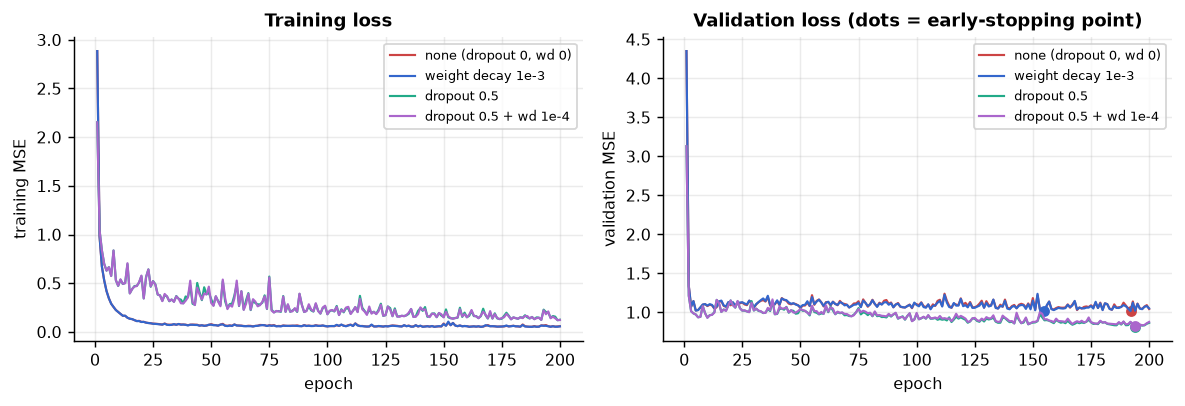

In [7]:
# Figure 2: training and validation curves for the four configurations.
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2))
for (name, hist), colr in zip(reg_hist.items(), ["#c44", "#36c", "#2a8", "#a6c"]):
    axes[0].plot(hist[:, 0] + 1, hist[:, 1], color=colr, lw=1.2, label=name)
    axes[1].plot(hist[:, 0] + 1, hist[:, 2], color=colr, lw=1.2, label=name)
    k = int(np.argmin(hist[:, 2]))
    axes[1].plot(hist[k, 0] + 1, hist[k, 2], "o", color=colr, ms=5)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training MSE"); axes[0].set_title("Training loss")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation MSE")
axes[1].set_title("Validation loss (dots = early-stopping point)")
axes[0].legend(fontsize=7); axes[1].legend(fontsize=7)
for a in axes: a.grid(alpha=.25)
fig.tight_layout()

<p class="caption"><b>Figure 2.</b> Left: training MSE per epoch. Without regularisation it falls towards zero — the network memorises 1,934 compounds exactly. Right: validation MSE, with the early-stopping point of each run marked; the unregularised run reaches its best validation loss early and then deteriorates, while the dropout runs train more slowly and plateau. The printed train-validation gaps quantify the memorisation.</p>

The unregularised curve is the canonical overfitting picture and the reason early stopping exists: the training MSE falls below 0.1 while the validation MSE sits above 1.0, a gap of about one log unit squared. Dropout closes roughly a quarter of that gap and does improve the validation loss, but the printed test R² shows what it does not fix — even the best-regularised network remains near zero on the scaffold split. Regularisation controls memorisation; it cannot create transfer to chemistry the model has never seen. The next section changes what the network sees rather than how it is penalised.

### 5.1 Two settings that break training silently

Before blaming the architecture, check the learning rate and the initialisation. Too large a step size makes the validation loss oscillate or diverge; an all-zeros initialisation leaves every hidden unit identical for ever, because symmetric units receive identical gradients.

lr = 1e-05: best validation MSE 1.134 at epoch 100, final training MSE 1.271
lr = 1e-03: best validation MSE 0.886 at epoch 98, final training MSE 0.181
lr = 1e-01: best validation MSE 1.153 at epoch 15, final training MSE 1.224
initialisation default (He-style)  : validation MSE after 60 epochs 1.075
initialisation all zeros           : validation MSE after 60 epochs 22.089
initialisation inflated (x20)      : validation MSE after 60 epochs 1585.380


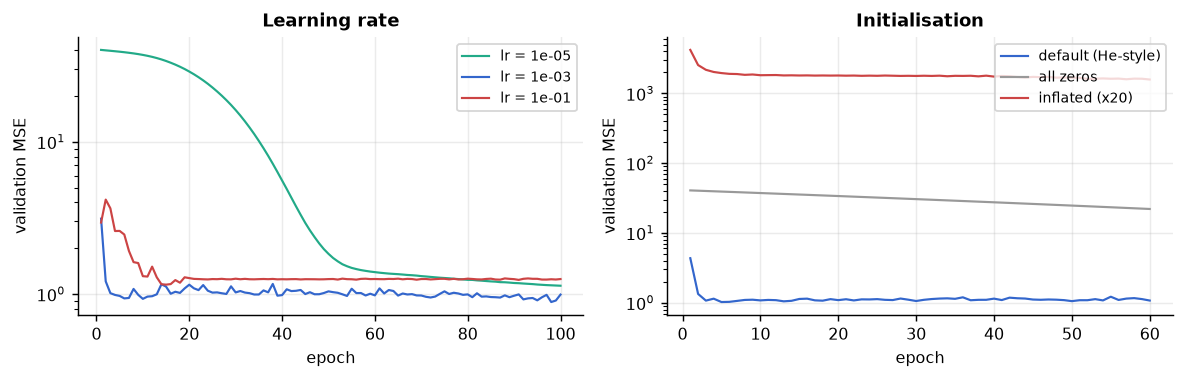

In [8]:
# Learning rate and initialisation: two failure modes, measured.
lr_hist = {}
for lr in [1e-5, 1e-3, 1e-1]:
    _, h, v = train_mlp(Xfp, TRs, VAs, dropout=0.5, lr=lr, epochs=100, patience=100)
    lr_hist[lr] = h
    print(f"lr = {lr:.0e}: best validation MSE {v:.3f} at epoch {int(h[np.argmin(h[:,2]),0])+1}, "
          f"final training MSE {h[-1,1]:.3f}")

init_hist = {}
Xtr_, ytr_ = torch.tensor(Xfp[TRs]), torch.tensor(y[TRs]).view(-1, 1)
Xva_, yva_ = torch.tensor(Xfp[VAs]), torch.tensor(y[VAs]).view(-1, 1)
for label in ["default (He-style)", "all zeros", "inflated (x20)"]:
    net = make_mlp(Xfp.shape[1], dropout=0.0, seed=0)
    with torch.no_grad():
        for mod in net:
            if isinstance(mod, nn.Linear):
                if label == "all zeros":
                    mod.weight.zero_(); mod.bias.zero_()
                elif label.startswith("inflated"):
                    mod.weight.mul_(20.0)
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=0.0)
    hh = []
    for ep in range(60):
        net.train(); perm = torch.randperm(len(TRs))
        for i in range(0, len(TRs), 64):
            idx = perm[i:i+64]; opt.zero_grad()
            ((net(Xtr_[idx]) - ytr_[idx]) ** 2).mean().backward(); opt.step()
        net.eval()
        with torch.no_grad():
            hh.append((ep, ((net(Xtr_) - ytr_) ** 2).mean().item(),
                       ((net(Xva_) - yva_) ** 2).mean().item()))
    init_hist[label] = np.array(hh)
    print(f"initialisation {label:20s}: validation MSE after 60 epochs {init_hist[label][-1,2]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.0))
for (lr, h), colr in zip(lr_hist.items(), ["#2a8", "#36c", "#c44"]):
    axes[0].plot(h[:, 0] + 1, h[:, 2], color=colr, lw=1.2, label=f"lr = {lr:.0e}")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation MSE"); axes[0].legend(fontsize=7.5)
axes[0].set_title("Learning rate"); axes[0].set_yscale("log")
for (label, h), colr in zip(init_hist.items(), ["#36c", "#999", "#c44"]):
    axes[1].plot(h[:, 0] + 1, h[:, 2], color=colr, lw=1.2, label=label)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation MSE"); axes[1].legend(fontsize=7.5)
axes[1].set_title("Initialisation"); axes[1].set_yscale("log")
for a in axes: a.grid(alpha=.25)
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> Validation MSE on a logarithmic scale. Left: three learning rates spanning four orders of magnitude with everything else fixed — the largest is unstable, the smallest has barely moved within the epoch budget, and only the middle one behaves. Right: three initialisations; the all-zeros network never leaves its starting loss because every hidden unit receives an identical gradient, and the inflated initialisation starts orders of magnitude worse and must first be undone by the optimiser. Neither failure produces an error message, only a bad number.</p>

## 6. Representation beats depth: an honest comparison with gradient boosting

Two changes, neither of them architectural. First, **reduce and scale the input**: project the 2,048 binary bits onto their 256 leading singular vectors (fitted on the training set only — doing it on all the data is leakage) and standardise the result, so every input has comparable scale and the first layer sees 256 informative coordinates instead of 2,048 sparse indicators. Second, **select the learning rate and the dropout on the validation set**, not by instinct.

Then the comparison the reader deserves: the tuned MLP against LightGBM with its default-ish settings, on both splits, with the same features and the same training compounds.

In [9]:
# Validation-set sweep over learning rate, dropout and width (scaffold split, SVD features).
from sklearn.decomposition import TruncatedSVD
def svd_features(tr, n_comp=256):
    svd = TruncatedSVD(n_components=n_comp, random_state=0).fit(Xfp[tr])
    Z = svd.transform(Xfp).astype(np.float32)
    Z = (Z - Z[tr].mean(0)) / (Z[tr].std(0) + 1e-6)
    return Z, svd
Xsvd_s, svd_s = svd_features(TRs)
print(f"SVD on the training fingerprints: {Xsvd_s.shape[1]} components, "
      f"{svd_s.explained_variance_ratio_.sum():.1%} of the bit-matrix variance retained")
t0 = time.perf_counter()
sweep = []
for hidden, dropout, lr in itertools.product([256], [0.2, 0.5], [3e-4, 1e-3]):
    net, hist, val = train_mlp(Xsvd_s, TRs, VAs, hidden=hidden, dropout=dropout, lr=lr,
                               epochs=300, patience=40)
    pred = predict(net, Xsvd_s, TEs)
    sweep.append({"hidden": hidden, "dropout": dropout, "lr": lr, "epochs": len(hist),
                  "val MSE": val, "test R2": r2_score(y[TEs], pred)})
sw = pd.DataFrame(sweep).sort_values("val MSE")
print(sw.round(4).to_string(index=False))
best_cfg = sw.iloc[0]
print(f"\nselected on validation MSE: dropout {best_cfg['dropout']}, lr {best_cfg['lr']} "
      f"({time.perf_counter()-t0:.0f} s for {len(sweep)} configurations)")

SVD on the training fingerprints: 256 components, 90.6% of the bit-matrix variance retained
 hidden  dropout     lr  epochs  val MSE  test R2
    256      0.5 0.0010     300   0.6027   0.2593
    256      0.2 0.0010     300   0.7056   0.1440
    256      0.5 0.0003     300   0.7822   0.0440
    256      0.2 0.0003     300   0.8935  -0.1325

selected on validation MSE: dropout 0.5, lr 0.001 (28 s for 4 configurations)


In [10]:
# The comparison: tuned MLP vs LightGBM, raw bits vs SVD features, both splits.
rows = []
for split, (tr, va, te) in {"scaffold": (TRs, VAs, TEs), "random": (TRr, VAr, TEr)}.items():
    Z, _ = svd_features(tr)
    net_b, _, _ = train_mlp(Xfp, tr, va, dropout=0.5, lr=1e-3, epochs=300, patience=40)
    net_z, _, _ = train_mlp(Z, tr, va, dropout=float(best_cfg["dropout"]), lr=float(best_cfg["lr"]),
                            epochs=300, patience=40)
    gbm = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31,
                            random_state=0, verbose=-1).fit(Xfp[tr], y[tr])
    for name, pred in [("MLP on raw 2048 bits", predict(net_b, Xfp, te)),
                       ("MLP on 256 scaled SVD components", predict(net_z, Z, te)),
                       ("LightGBM on raw 2048 bits", gbm.predict(Xfp[te])),
                       ("predict the training mean", np.full(len(te), y[tr].mean()))]:
        rows.append({"split": split, "model": name, "test R2": r2_score(y[te], pred),
                     "MAE": mean_absolute_error(y[te], pred),
                     "RMSE": float(np.sqrt(((y[te] - pred) ** 2).mean()))})
comp = pd.DataFrame(rows)
print(comp.round(3).to_string(index=False))
sc = comp[comp["split"] == "scaffold"].set_index("model")
print(f"\nscaffold split: changing the representation moved the MLP from R2 "
      f"{sc.loc['MLP on raw 2048 bits','test R2']:+.3f} to {sc.loc['MLP on 256 scaled SVD components','test R2']:+.3f}; "
      f"LightGBM on the raw bits reaches {sc.loc['LightGBM on raw 2048 bits','test R2']:+.3f}")

  File "/usr/lib/python3.11/site-packages/joblib/externals/loky/backend/context.py", line 249, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_darwin()
                         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/lib/python3.11/site-packages/joblib/externals/loky/backend/context.py", line 318, in _count_physical_cores_darwin
    return int(cpu_info)
           ^^^^^^^^^^^^^
   split                            model  test R2   MAE  RMSE
scaffold             MLP on raw 2048 bits    0.009 0.784 1.019
scaffold MLP on 256 scaled SVD components    0.259 0.691 0.881
scaffold        LightGBM on raw 2048 bits    0.283 0.679 0.867
scaffold        predict the training mean   -0.267 0.939 1.152
  random             MLP on raw 2048 bits    0.429 0.624 0.829
  random MLP on 256 scaled SVD components    0.499 0.599 0.776
  random        LightGBM on raw 2048 bits    0.531 0.575 0.751
  random        predict the training mean   -0.009 0.878 1.101

scaffold split: changin

correlation between the two models' predictions: 0.813; their average: R2 +0.324


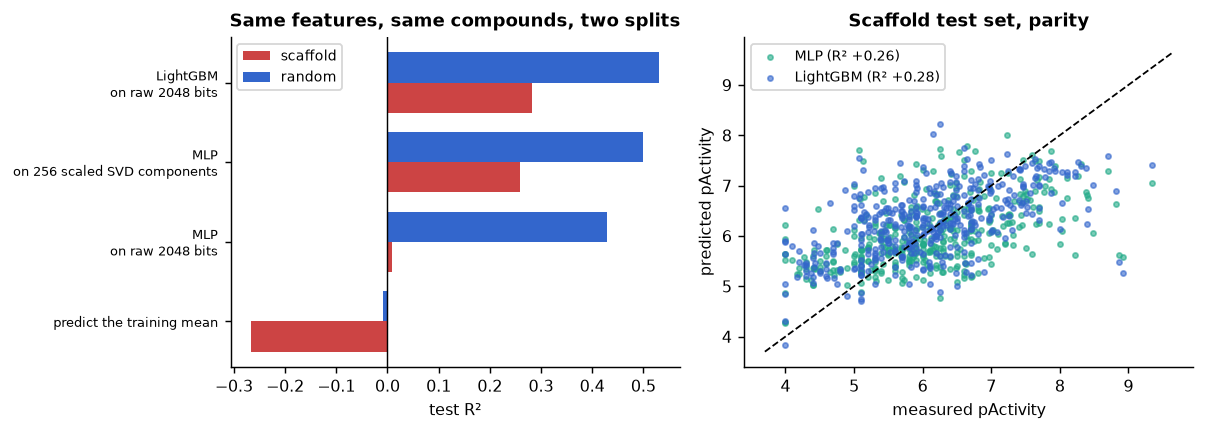

In [11]:
# Figure 4: the comparison, and a parity plot of the two best models on the scaffold test set.
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.4))
order = ["predict the training mean", "MLP on raw 2048 bits",
         "MLP on 256 scaled SVD components", "LightGBM on raw 2048 bits"]
w = 0.38
for k, (split, colr) in enumerate([("scaffold", "#c44"), ("random", "#36c")]):
    vals = [comp[(comp["split"] == split) & (comp["model"] == m)]["test R2"].iloc[0] for m in order]
    axes[0].barh(np.arange(len(order)) + (k - 0.5) * w, vals, height=w, color=colr, label=split)
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels([m.replace(" on ", "\non ") for m in order], fontsize=7)
axes[0].axvline(0, color="k", lw=.8); axes[0].set_xlabel("test R²"); axes[0].legend(fontsize=7.5)
axes[0].set_title("Same features, same compounds, two splits")
Zs, _ = svd_features(TRs)
net_z2, _, _ = train_mlp(Zs, TRs, VAs, dropout=float(best_cfg["dropout"]), lr=float(best_cfg["lr"]),
                         epochs=300, patience=40)
p_mlp = predict(net_z2, Zs, TEs)
p_gbm = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, random_state=0,
                          verbose=-1).fit(Xfp[TRs], y[TRs]).predict(Xfp[TEs])
axes[1].scatter(y[TEs], p_mlp, s=8, alpha=.6, color="#2a8", label=f"MLP (R² {r2_score(y[TEs], p_mlp):+.2f})")
axes[1].scatter(y[TEs], p_gbm, s=8, alpha=.6, color="#36c", label=f"LightGBM (R² {r2_score(y[TEs], p_gbm):+.2f})")
lims = [y[TEs].min() - 0.3, y[TEs].max() + 0.3]
axes[1].plot(lims, lims, "k--", lw=1)
axes[1].set_xlabel("measured pActivity"); axes[1].set_ylabel("predicted pActivity")
axes[1].set_title("Scaffold test set, parity"); axes[1].legend(fontsize=7.5)
fig.tight_layout()
print(f"correlation between the two models' predictions: {np.corrcoef(p_mlp, p_gbm)[0,1]:.3f}; "
      f"their average: R2 {r2_score(y[TEs], (p_mlp+p_gbm)/2):+.3f}")

<p class="caption"><b>Figure 4.</b> Left: test R² of four models on both splits, including the trivial baseline of predicting the training mean. Right: parity plot on the scaffold test set for the tuned MLP and for LightGBM; both regress towards the mean on the least potent compounds, which is what a scaffold split does to any similarity-based model. The printed line gives the correlation between the two models' predictions and the R² of their simple average.</p>

Three conclusions, in the order a referee would want them.

1. **The representation, not the architecture, was the problem.** Projecting the sparse bits onto 256 scaled components turned a network that predicted nothing into a competitive one, without changing a single layer. On sparse binary inputs this preprocessing matters more than depth, width or dropout.
2. **Gradient boosting still wins, on both splits.** The margin is modest but consistent, and it is obtained with no tuning and in a fraction of the time. This is the finding of the tabular-data literature<sup class="c"><a href="#r14">[14]</a><a href="#r15">[15]</a></sup> and of the corrected cheminformatics comparison<sup class="c"><a href="#r17">[17]</a></sup>, reproduced here.
3. **The split dominates everything.** The two competitive models lose roughly half their R² moving from the random to the scaffold split, and the MLP on raw bits does worse than that — it collapses from a usable random-split score to approximately zero. Either way the difference between architectures is smaller than the difference between validation protocols, and a paper that reports a deep model's advantage under a random split has not yet made a claim about new chemistry<sup class="c"><a href="#r35">[35]</a></sup>.

### 6.1 How large is a difference of 0.03 in R²?

Retraining the same network with a different seed changes its test score, and the size of that change is the yardstick for any claimed improvement.

model  LightGBM  MLP (SVD)
seed                      
0         0.291      0.250
1         0.284      0.213
2         0.287      0.206
3         0.290      0.212
4         0.272      0.207

             mean     std     min     max
model                                    
LightGBM   0.2848  0.0075  0.2723  0.2911
MLP (SVD)  0.2177  0.0185  0.2056  0.2503
spread of the MLP across seeds: 0.045 R2 units; difference between the two model means: +0.067


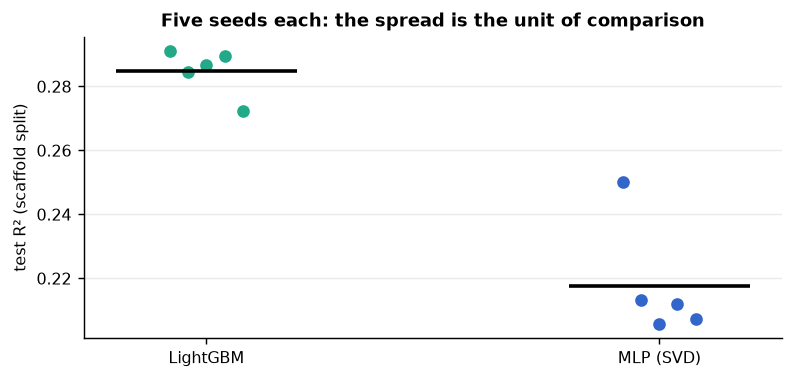

In [12]:
# Seed-to-seed variability of the tuned MLP, against the variability of LightGBM.
seed_rows = []
for seed in range(5):
    net_s, _, _ = train_mlp(Zs, TRs, VAs, dropout=float(best_cfg["dropout"]),
                            lr=float(best_cfg["lr"]), epochs=250, patience=30, seed=seed)
    seed_rows.append({"seed": seed, "model": "MLP (SVD)",
                      "test R2": r2_score(y[TEs], predict(net_s, Zs, TEs))})
for seed in range(5):
    g_s = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, subsample=0.8, subsample_freq=1,
                            colsample_bytree=0.8, random_state=seed, verbose=-1).fit(Xfp[TRs], y[TRs])
    seed_rows.append({"seed": seed, "model": "LightGBM",
                      "test R2": r2_score(y[TEs], g_s.predict(Xfp[TEs]))})
seeds = pd.DataFrame(seed_rows)
print(seeds.pivot(index="seed", columns="model", values="test R2").round(3).to_string())
agg = seeds.groupby("model")["test R2"].agg(["mean", "std", "min", "max"])
print()
print(agg.round(4).to_string())
print(f"spread of the MLP across seeds: {agg.loc['MLP (SVD)','max'] - agg.loc['MLP (SVD)','min']:.3f} R2 units; "
      f"difference between the two model means: {agg.loc['LightGBM','mean'] - agg.loc['MLP (SVD)','mean']:+.3f}")

fig, ax = plt.subplots(figsize=(6.2, 3.0))
for k2, (model, g) in enumerate(seeds.groupby("model")):
    ax.plot(np.full(len(g), k2) + np.linspace(-.08, .08, len(g)), g["test R2"], "o",
            color=["#2a8", "#36c"][k2], ms=6)
    ax.hlines(g["test R2"].mean(), k2 - 0.2, k2 + 0.2, color="k", lw=2)
ax.set_xticks([0, 1]); ax.set_xticklabels(sorted(seeds["model"].unique()))
ax.set_ylabel("test R² (scaffold split)")
ax.set_title("Five seeds each: the spread is the unit of comparison"); ax.grid(alpha=.25, axis="y")
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> Test R² of five independently seeded runs of the tuned MLP and of five differently seeded LightGBM models (with row and column subsampling switched on so that the seed matters), with the means marked. The printed spread across seeds is the yardstick against which any reported architectural improvement must be measured.</p>

<div class="exercise"><h4>Exercise 1</h4>
<p>Keep the architecture and change only the number of SVD components (64, 128, 256, 512). Plot validation MSE against the number of components and report where it bottoms out. Then repeat with <code>StandardScaler</code> removed — i.e. unscaled components — and report how much of the gain in Section 6 came from the projection and how much from the scaling.</p></div>

## 7. Learning curves: how much data would it take?

The question behind "should we use deep learning" is usually "would more data change the answer". A learning curve — performance against training-set size, with the same validation and test sets — is the way to ask it.

In [13]:
# Learning curves on the scaffold split: MLP, LightGBM and a ridge baseline.
from sklearn.linear_model import RidgeCV
sizes = [200, 400, 800, 1400, len(TRs)]
rng_lc = np.random.default_rng(0)
lc = []
t0 = time.perf_counter()
for n in sizes:
    sub = rng_lc.choice(TRs, n, replace=False) if n < len(TRs) else TRs
    Zn, _ = svd_features(sub, n_comp=min(128, n // 2))   # the code cannot be wider than the data
    net_n, _, _ = train_mlp(Zn, sub, VAs, dropout=float(best_cfg["dropout"]),
                            lr=float(best_cfg["lr"]), epochs=250, patience=30)
    g_n = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=0,
                            verbose=-1).fit(Xfp[sub], y[sub])
    r_n = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(Xfp[sub], y[sub])
    lc.append({"n_train": n,
               "MLP (SVD)": r2_score(y[TEs], predict(net_n, Zn, TEs)),
               "LightGBM": r2_score(y[TEs], g_n.predict(Xfp[TEs])),
               "ridge on bits": r2_score(y[TEs], r_n.predict(Xfp[TEs]))})
lcdf = pd.DataFrame(lc)
print(lcdf.round(3).to_string(index=False))
print(f"\n({time.perf_counter()-t0:.0f} s for {len(sizes)} training-set sizes x 3 models)")
print(f"R2 gained by going from {sizes[0]} to {sizes[-1]} training compounds: "
      + ", ".join(f"{c} {lcdf[c].iloc[-1]-lcdf[c].iloc[0]:+.3f}" for c in ["MLP (SVD)", "LightGBM", "ridge on bits"]))

 n_train  MLP (SVD)  LightGBM  ridge on bits
     200     -1.888     0.075          0.096
     400     -1.023    -0.025          0.062
     800     -0.545     0.043          0.141
    1400     -0.200     0.249          0.166
    1934      0.167     0.285          0.183

(19 s for 5 training-set sizes x 3 models)
R2 gained by going from 200 to 1934 training compounds: MLP (SVD) +2.056, LightGBM +0.210, ridge on bits +0.087


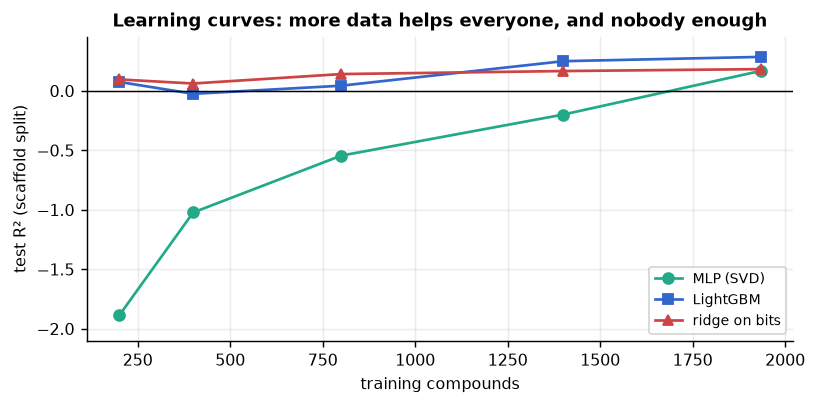

In [14]:
# Figure 6: the learning curves.
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for col, colr, mk in [("MLP (SVD)", "#2a8", "o"), ("LightGBM", "#36c", "s"), ("ridge on bits", "#c44", "^")]:
    ax.plot(lcdf["n_train"], lcdf[col], mk + "-", color=colr, label=col)
ax.axhline(0, color="k", lw=.8); ax.set_ylim(-2.1, 0.45)
ax.set_xlabel("training compounds"); ax.set_ylabel("test R² (scaffold split)")
ax.set_title("Learning curves: more data helps everyone, and nobody enough")
ax.legend(fontsize=7.5); ax.grid(alpha=.25)
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Test R² on the scaffold test set against the number of training compounds, for the MLP on SVD features, LightGBM and a ridge baseline on raw bits (the SVD width is capped at half the sample size, so the code cannot be wider than the data). None of the curves has flattened at the full training-set size. The network is far behind everywhere and is catastrophically bad below a few hundred compounds, while ridge regression — the simplest model of the three — is the best of them up to roughly a thousand compounds, after which LightGBM overtakes it.</p>

Three readings. First, the curves not having flattened means the dataset is the binding constraint, not the model class: the right investment is more measurements (or data from related kinases), not a deeper network. Second, the crossover between ridge and LightGBM is the practical form of the bias-variance trade-off — with a few hundred compounds the flexible model has nothing to be flexible with, which is also the regime in which pretrained representations (Section 8) are supposed to help. Third, the network never approaches the other two anywhere along the curve, and its small-sample behaviour (large negative R²) is a warning about deploying neural models on project-sized datasets.

## 8. Pretrained representations: what they are, and an offline stand-in

The most useful thing deep learning currently offers a small laboratory is not a model to train but a **representation to borrow**. The pattern is always the same:

1. A large model is pretrained on a *self-supervised* task over a huge unlabelled corpus — masked-token prediction over tens of millions of SMILES strings for chemical language models such as ChemBERTa<sup class="c"><a href="#r22">[22]</a></sup> and MoLFormer<sup class="c"><a href="#r23">[23]</a></sup>, or over hundreds of millions of protein sequences for ESM-2<sup class="c"><a href="#r25">[25]</a><a href="#r26">[26]</a></sup>; translation between equivalent chemical representations is another such objective<sup class="c"><a href="#r24">[24]</a></sup>.
2. Its internal activations for a new molecule or sequence — the **embedding**, typically a few hundred to a few thousand numbers — are extracted once, with the weights **frozen**.
3. Those embeddings become the feature matrix of an ordinary model: logistic regression, random forest, gradient boosting. No gradients, no GPU, no fine-tuning.

That third step is what makes the approach practical here: embedding 3,000 molecules is a single forward pass, after which the modelling is the pipeline of Unit 11. Transfer learning of this kind helps most when the labelled set is small and the pretraining corpus covers the relevant chemistry or protein family; it helps least when the labelled set is already large and homogeneous, which is the regime of most single-target QSAR<sup class="c"><a href="#r31">[31]</a><a href="#r32">[32]</a></sup>.

<div class="box bridge"><h4>Substitution, stated explicitly</h4>
<p><strong>This notebook does not use a pretrained model.</strong> The course's build environment has no network access, so neither ChemBERTa weights nor ESM-2 weights can be downloaded, and nothing of that kind is bundled with the frozen datasets. What follows is therefore a <em>transparent surrogate</em>: an unsupervised <strong>autoencoder</strong><sup class="c"><a href="#r29">[29]</a><a href="#r30">[30]</a></sup> and a truncated-SVD embedding, both trained in this notebook on the <em>training</em> fingerprints only. They reproduce the <em>mechanics</em> of the frozen-embedding workflow — unsupervised objective, frozen encoder, classical model on top — and nothing else. They are not pretrained models: they see about two thousand molecules, not tens of millions, and no chemistry beyond this dataset. Do not read the numbers below as evidence about ChemBERTa or ESM-2; read them as evidence about what compression alone can and cannot buy. Published evaluations of real pretrained molecular representations are referenced at the end<sup class="c"><a href="#r22">[22]</a><a href="#r23">[23]</a><a href="#r20">[20]</a></sup>.</p></div>

In [15]:
# A fingerprint autoencoder: 2048 -> 256 -> 32 -> 256 -> 2048, trained unsupervised on the training set.
torch.manual_seed(0)
encoder = nn.Sequential(nn.Linear(2048, 256), nn.ReLU(), nn.Linear(256, 32))
decoder = nn.Sequential(nn.Linear(32, 256), nn.ReLU(), nn.Linear(256, 2048))
autoenc = nn.Sequential(encoder, decoder)
opt_ae = torch.optim.AdamW(autoenc.parameters(), lr=1e-3, weight_decay=1e-5)
bce = nn.BCEWithLogitsLoss()
Xtr_t, Xva_t = torch.tensor(Xfp[TRs]), torch.tensor(Xfp[VAs])
ae_hist = []
t0 = time.perf_counter()
for ep in range(60):
    autoenc.train()
    perm = torch.randperm(len(TRs))
    for i in range(0, len(TRs), 128):
        idx = perm[i:i + 128]
        opt_ae.zero_grad(); bce(autoenc(Xtr_t[idx]), Xtr_t[idx]).backward(); opt_ae.step()
    autoenc.eval()
    with torch.no_grad():
        ae_hist.append((ep, bce(autoenc(Xtr_t), Xtr_t).item(), bce(autoenc(Xva_t), Xva_t).item()))
ae_hist = np.array(ae_hist)
with torch.no_grad():
    Zae = encoder(torch.tensor(Xfp)).numpy()
    rec = (torch.sigmoid(autoenc(torch.tensor(Xfp[TEs]))) > 0.5).numpy().astype(np.float32)
tp = float(((rec == 1) & (Xfp[TEs] == 1)).sum()); fp_ = float(((rec == 1) & (Xfp[TEs] == 0)).sum())
fn = float(((rec == 0) & (Xfp[TEs] == 1)).sum())
print(f"autoencoder trained in {time.perf_counter()-t0:.1f} s; validation reconstruction loss "
      f"{ae_hist[0,2]:.4f} -> {ae_hist[-1,2]:.4f}")
print(f"bit reconstruction on the test compounds: recall {tp/(tp+fn):.3f}, precision {tp/max(tp+fp_,1):.3f} "
      f"-> a 32-number code keeps most but not all of a 2048-bit fingerprint")

autoencoder trained in 5.0 s; validation reconstruction loss 0.1074 -> 0.0894
bit reconstruction on the test compounds: recall 0.584, precision 0.741 -> a 32-number code keeps most but not all of a 2048-bit fingerprint


In [16]:
# Three representations, the same two classical models on top (frozen-embedding workflow).
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
svd32 = TruncatedSVD(n_components=32, random_state=0).fit(Xfp[TRs])
Zsvd32 = svd32.transform(Xfp).astype(np.float32)
reps = {"raw 2048 bits": Xfp, "SVD-32 embedding": Zsvd32, "autoencoder-32 embedding": Zae}
rows = []
for name, F in reps.items():
    rr = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(F[TRs], y[TRs])
    lgr = LogisticRegression(max_iter=3000).fit(F[TRs], ycls[TRs])
    gb = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=0,
                           verbose=-1).fit(F[TRs], y[TRs])
    rows.append({"representation": name, "dimensions": F.shape[1],
                 "ridge R2": r2_score(y[TEs], rr.predict(F[TEs])),
                 "LightGBM R2": r2_score(y[TEs], gb.predict(F[TEs])),
                 "logistic ROC-AUC": roc_auc_score(ycls[TEs], lgr.predict_proba(F[TEs])[:, 1])})
emb = pd.DataFrame(rows)
print(emb.round(3).to_string(index=False))
print(f"\nSVD-32 retains {svd32.explained_variance_ratio_.sum():.1%} of the bit-matrix variance")
print("the 32-dimensional codes lose accuracy relative to the raw bits on every model -> "
      "compression of 2,000 molecules is not pretraining")

          representation  dimensions  ridge R2  LightGBM R2  logistic ROC-AUC
           raw 2048 bits        2048     0.183        0.285             0.815
        SVD-32 embedding          32     0.048        0.162             0.689
autoencoder-32 embedding          32     0.016        0.209             0.645

SVD-32 retains 55.9% of the bit-matrix variance
the 32-dimensional codes lose accuracy relative to the raw bits on every model -> compression of 2,000 molecules is not pretraining


Spearman correlation between autoencoder dim 1 and pActivity: -0.204


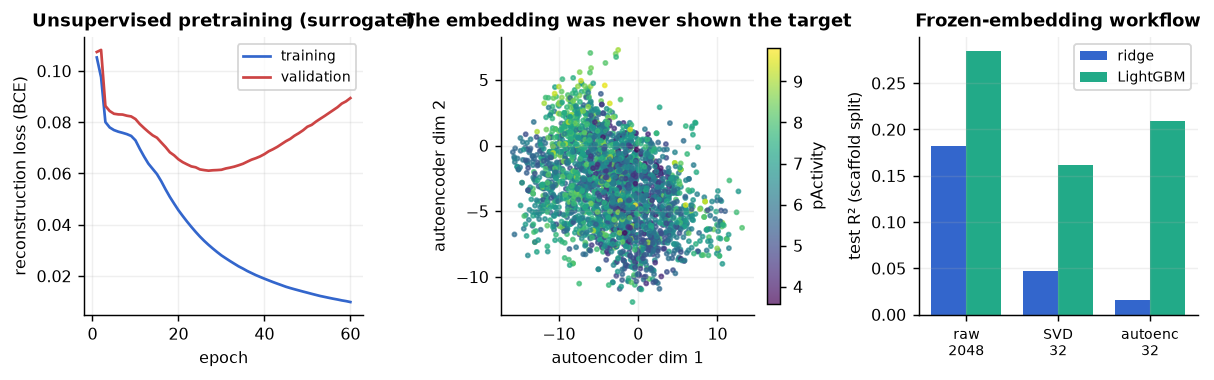

In [17]:
# Figure 7: autoencoder training curve, the embedding space, and the representation comparison.
fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.0))
axes[0].plot(ae_hist[:, 0] + 1, ae_hist[:, 1], color="#36c", label="training")
axes[0].plot(ae_hist[:, 0] + 1, ae_hist[:, 2], color="#c44", label="validation")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("reconstruction loss (BCE)")
axes[0].set_title("Unsupervised pretraining (surrogate)"); axes[0].legend(fontsize=7.5)
sc_emb = axes[1].scatter(Zae[:, 0], Zae[:, 1], c=y, s=5, cmap="viridis", alpha=.7)
fig.colorbar(sc_emb, ax=axes[1], fraction=.046, label="pActivity")
axes[1].set_xlabel("autoencoder dim 1"); axes[1].set_ylabel("autoencoder dim 2")
axes[1].set_title("The embedding was never shown the target")
xs = np.arange(len(emb)); w = 0.38
axes[2].bar(xs - w/2, emb["ridge R2"], width=w, color="#36c", label="ridge")
axes[2].bar(xs + w/2, emb["LightGBM R2"], width=w, color="#2a8", label="LightGBM")
axes[2].set_xticks(xs); axes[2].set_xticklabels(["raw\n2048", "SVD\n32", "autoenc\n32"], fontsize=7.5)
axes[2].set_ylabel("test R² (scaffold split)"); axes[2].legend(fontsize=7.5)
axes[2].set_title("Frozen-embedding workflow")
for a in axes: a.grid(alpha=.2)
fig.tight_layout()
print(f"Spearman correlation between autoencoder dim 1 and pActivity: "
      f"{pd.Series(Zae[:,0]).corr(pd.Series(y), method='spearman'):+.3f}")

<p class="caption"><b>Figure 7.</b> Left: the surrogate autoencoder's reconstruction loss on training and validation fingerprints; the two curves stay close, so the 32-number bottleneck is not memorising. Centre: the test compounds in the first two embedding dimensions, coloured by measured potency — the encoder never saw the target, and the printed rank correlation with potency is weak. Right: test R² of ridge and LightGBM on the raw bits and on the two 32-dimensional codes; both codes lose accuracy.</p>

The honest verdict of the surrogate experiment is a negative one, and it is exactly the right lesson to carry into reading the pretrained-model literature: **dimensionality reduction on your own small dataset is not transfer learning.** A 32-number code trained on two thousand molecules throws away information that the downstream model could have used, as the reconstruction recall and the three R² values show. What makes a real pretrained representation different is not the architecture of the encoder but the *corpus*: tens of millions of molecules or hundreds of millions of protein sequences, carrying statistics about chemistry that no single project's data contains<sup class="c"><a href="#r22">[22]</a><a href="#r23">[23]</a><a href="#r25">[25]</a></sup>. When you do have such embeddings, the workflow is the one coded above — freeze, embed once, model classically, and compare against the fingerprint baseline on the same split, because published comparisons find the advantage of learned representations over well-tuned fingerprint baselines to be modest and dataset-dependent<sup class="c"><a href="#r20">[20]</a><a href="#r21">[21]</a></sup>.

### 8.1 How wide must a code be?

If 32 numbers lose information, how many are enough? The sweep below answers it for the SVD embedding, which costs seconds to refit at any width.

 dimensions  variance retained  ridge R2  LightGBM R2
          8              0.280    -0.007        0.061
         16              0.416     0.027        0.186
         32              0.559     0.048        0.164
         64              0.693     0.087        0.164
        128              0.810     0.127        0.164
        256              0.906     0.205        0.195
        512              0.970     0.232        0.206


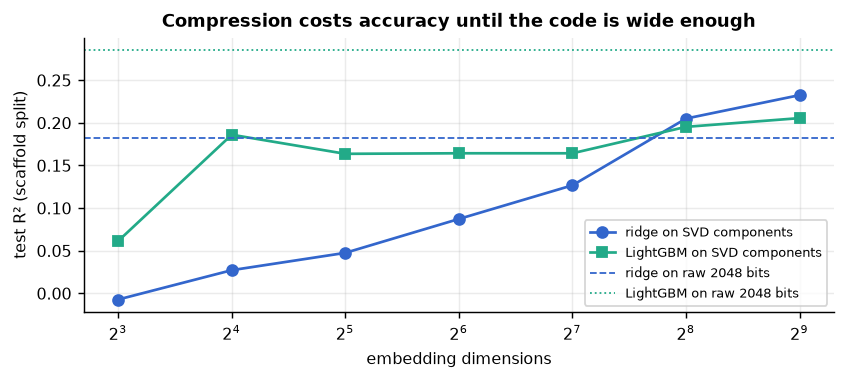

In [18]:
# Figure 8: accuracy against embedding width.
dims = [8, 16, 32, 64, 128, 256, 512]
dim_rows = []
for d in dims:
    sv = TruncatedSVD(n_components=d, random_state=0).fit(Xfp[TRs])
    F = sv.transform(Xfp).astype(np.float32)
    rr = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(F[TRs], y[TRs])
    gb = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=0,
                           verbose=-1).fit(F[TRs], y[TRs])
    dim_rows.append({"dimensions": d, "variance retained": sv.explained_variance_ratio_.sum(),
                     "ridge R2": r2_score(y[TEs], rr.predict(F[TEs])),
                     "LightGBM R2": r2_score(y[TEs], gb.predict(F[TEs]))})
dimdf = pd.DataFrame(dim_rows)
print(dimdf.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(6.6, 3.0))
ax.plot(dimdf["dimensions"], dimdf["ridge R2"], "o-", color="#36c", label="ridge on SVD components")
ax.plot(dimdf["dimensions"], dimdf["LightGBM R2"], "s-", color="#2a8", label="LightGBM on SVD components")
ax.axhline(emb.loc[0, "ridge R2"], color="#36c", ls="--", lw=1, label="ridge on raw 2048 bits")
ax.axhline(emb.loc[0, "LightGBM R2"], color="#2a8", ls=":", lw=1, label="LightGBM on raw 2048 bits")
ax.set_xscale("log", base=2); ax.set_xlabel("embedding dimensions")
ax.set_ylabel("test R² (scaffold split)"); ax.legend(fontsize=7)
ax.set_title("Compression costs accuracy until the code is wide enough"); ax.grid(alpha=.25)
fig.tight_layout()

<p class="caption"><b>Figure 8.</b> Test R² of ridge regression and LightGBM on SVD embeddings of increasing width, with the raw-fingerprint results as horizontal references. Narrow codes lose accuracy. Ridge regression improves steadily with width and eventually passes its own raw-bit baseline — the projection also denoises — while LightGBM, which handles the raw sparse bits well, never recovers its raw-bit score from any compressed code. The width at which the curves level off is the same order as the 256 components that made the MLP of Section 6 competitive.</p>

## 9. Graph neural networks and chemprop: pointers, not a tutorial

A **graph neural network** treats a molecule as a graph of atoms and bonds and learns a representation by passing messages along the bonds, so the featurisation is learned rather than hashed<sup class="c"><a href="#r18">[18]</a><a href="#r19">[19]</a></sup>. `chemprop`, the directed message-passing implementation, is the standard reference tool and is what you should reach for if a project genuinely needs a learned molecular representation on tens of thousands of compounds. Two findings temper the enthusiasm: on the MoleculeNet benchmarks and on industrial datasets, graph networks are not uniformly better than descriptor or fingerprint models<sup class="c"><a href="#r21">[21]</a></sup>, and a careful comparison on bioactivity data found descriptor-based models competitive with graph models across most tasks<sup class="c"><a href="#r20">[20]</a></sup>. The cheminformatics course covers graph representations in its own deep-learning unit; this course stops at the pointer.

## 10. A reading checklist for deep-learning papers

Apply this to every paper, including your own drafts. The six questions, with what a satisfactory answer looks like:

1. **What was the split?** Random, scaffold, time, or external? A random split on congeneric series answers a question nobody asked. Is the test set used only once?
2. **What is the baseline?** A fingerprint plus random forest or gradient boosting, tuned with the same budget as the neural model. A paper whose baseline is an untuned linear model has not made a comparison.
3. **How many runs?** A single seed is a single sample; architectures differ by less than seed-to-seed variation on small datasets.
4. **What was tuned, and on what?** Hyperparameters chosen on the test set invalidate the reported number.
5. **What compute, and what data?** GPU-hours and dataset size determine whether the result is reproducible by a reader and whether the comparison was fair.
6. **Is the code and are the weights released?** Without them the result is an anecdote<sup class="c"><a href="#r33">[33]</a><a href="#r34">[34]</a></sup>.

### 10.1 The checklist applied

Take two real papers, read together. Yang and co-workers' chemprop study<sup class="c"><a href="#r18">[18]</a></sup> reports a directed message-passing network against fingerprint and descriptor baselines on a large collection of public and proprietary datasets, with scaffold splits for several of them, released code, and an explicit discussion of hyperparameter optimisation — a strong answer to questions 1, 2, 4 and 6. Mayr and co-workers' large-scale comparison on ChEMBL<sup class="c"><a href="#r16">[16]</a></sup> concluded that feed-forward networks outperformed classical methods across thousands of assays. Robinson and co-workers then re-analysed that comparison<sup class="c"><a href="#r17">[17]</a></sup> and found that the conclusion depended on choices in the validation protocol; with corrected protocols the advantage of the neural models shrank considerably. The pair is the single best illustration in the field of why question 4 belongs on the list: the methods were not wrong, the comparison was.

The exercise below asks you to run the checklist yourself.

<div class="exercise"><h4>Exercise 2</h4>
<p>Choose one deep-learning QSAR paper published in the last two years in a journal your group reads, and answer the six questions in writing, one short paragraph each, with page or figure references. Then reproduce its <em>baseline</em> (not its network) on our ROCK1 scaffold split with the code in Section 6, and state whether the paper's reported baseline performance is consistent with what a competent baseline achieves here. Bring the two paragraphs and the number to the next group meeting.</p></div>

In [19]:
# Everything this notebook measured, in one table.
summary = pd.DataFrame([
    ("backpropagation by hand vs autograd", "agreement < 1e-3", "the chain rule, verified once"),
    ("MLP on raw bits (scaffold split)",
     f"R2 {sc.loc['MLP on raw 2048 bits','test R2']:+.3f}", "fails: sparse binary input, 1,934 compounds"),
    ("regularisation (no dropout, no decay)",
     f"train MSE {reg.loc[0,'final train MSE']:.3f} vs val {reg.loc[0,'final val MSE']:.3f}", "memorises the training set"),
    ("MLP on 256 scaled SVD components",
     f"R2 {sc.loc['MLP on 256 scaled SVD components','test R2']:+.3f}", "representation fixed what dropout could not"),
    ("LightGBM on raw bits (scaffold split)",
     f"R2 {sc.loc['LightGBM on raw 2048 bits','test R2']:+.3f}", "still ahead, with no tuning"),
    ("random vs scaffold split",
     f"{comp[(comp['split']=='random') & (comp['model']=='LightGBM on raw 2048 bits')]['test R2'].iloc[0]:+.3f}"
     f" vs {sc.loc['LightGBM on raw 2048 bits','test R2']:+.3f}", "protocol matters more than architecture"),
    ("learning curves",
     f"MLP {lcdf['MLP (SVD)'].iloc[0]:+.2f} -> {lcdf['MLP (SVD)'].iloc[-1]:+.2f} R2 over "
     f"{sizes[0]}-{sizes[-1]} compounds", "data is the binding constraint"),
    ("surrogate embeddings (32 dims)",
     f"ridge R2 {emb.loc[0,'ridge R2']:+.3f} (raw) vs {emb.loc[2,'ridge R2']:+.3f} (autoencoder)",
     "compression is not pretraining"),
], columns=["experiment", "result", "reading"])
summary

,experiment,result,reading
0,backpropagation by hand vs autograd,agreement < 1e-3,"the chain rule, verified once"
1,MLP on raw bits (scaffold split),R2 +0.009,"fails: sparse binary input, 1,934 compounds"
2,"regularisation (no dropout, no decay)",train MSE 0.058 vs val 1.042,memorises the training set
3,MLP on 256 scaled SVD components,R2 +0.259,representation fixed what dropout could not
4,LightGBM on raw bits (scaffold split),R2 +0.283,"still ahead, with no tuning"
5,random vs scaffold split,+0.531 vs +0.283,protocol matters more than architecture
6,learning curves,MLP -1.89 -> +0.17 R2 over 200-1934 compounds,data is the binding constraint
7,surrogate embeddings (32 dims),ridge R2 +0.183 (raw) vs +0.016 (autoencoder),compression is not pretraining


<p class="caption"><b>Table 1.</b> The eight experiments of this notebook. Three are negative results about neural networks on small molecular datasets; all three are reported, because they are the ones that change what a student should do next.</p>

<div class="box bridge"><h4>Bridge</h4>
<p>The chemistry-side treatment of neural models for molecules is the cheminformatics course's <a href="../../Cheminformatics/U15_Deep_Learning/index.html">U15 (deep learning)</a>, with representations in <a href="../../Cheminformatics/U5_Descriptors_Fingerprints/index.html">U5</a> and validation in <a href="../../Cheminformatics/U14_Validation/index.html">U14</a>. Structure prediction — the clearest success of deep learning in this field — is the subject of <a href="../../BGM324/02_Protein_Structure_Prediction/index.html">BGM324 unit 02</a>, and sequence analysis, the input of protein language models, of <a href="../../BGM324/01_Sequence_Alignment/index.html">unit 01</a>. The artificial-intelligence course develops neural networks from the algorithmic side: <a href="../../BGM411/Python/index.html">BGM411 study material</a>. Inside this course, <a href="../U13_Features_Dimensionality/index.html">Unit 13</a> built the SVD/PCA machinery that rescued the network here, <a href="../U14_Ensembles_Tuning/index.html">Unit 14</a> the gradient-boosting competitor, and <a href="../U24_Software_Engineering/index.html">Unit 24</a> explains how to package a training script so that the run card below can be regenerated by anyone.</p></div>

### 10.2 A run card for this notebook

The same checklist applied to the work you have just read: the cell below prints the configuration a reader would need to reproduce it.

In [20]:
# Run card: the reproducibility metadata of this notebook's own experiments.
card = f'''
RUN CARD - Unit 18 experiments
==============================
software     : torch {torch.__version__}, lightgbm {lgb.__version__}, scikit-learn {sklearn.__version__},
               rdkit {rdkit.__version__}, numpy {np.__version__}; CPU only, {torch.get_num_threads()} threads
seeds        : numpy 0, torch 0; every model refitted with random_state/seed = 0 unless swept
data         : rock1_chembl_curated.csv, {len(cmp_)} compounds with exact measurements,
               Morgan fingerprints radius 2 / 2048 bits computed in-notebook
splits       : scaffold (Bemis-Murcko, deterministic) {len(TRs)}/{len(VAs)}/{len(TEs)};
               random {len(TRr)}/{len(VAr)}/{len(TEr)}; test sets used once per model
architecture : {Xfp.shape[1]} or 256 inputs -> 256 -> 64 -> 1, ReLU, dropout {best_cfg["dropout"]},
               AdamW lr {best_cfg["lr"]}, weight decay 1e-4, batch 64, early stopping patience 30-40
tuning       : {len(sweep)} configurations compared on the VALIDATION set only (section 6)
runs         : 5 seeds for the headline comparison (section 6.1); spread reported
baselines    : LightGBM (500 trees, lr 0.05), ridge, and the training mean
headline     : scaffold-split test R2 - MLP(SVD) {sc.loc["MLP on 256 scaled SVD components","test R2"]:+.3f},
               LightGBM {sc.loc["LightGBM on raw 2048 bits","test R2"]:+.3f},
               MLP on raw bits {sc.loc["MLP on raw 2048 bits","test R2"]:+.3f}
pretrained   : NONE used; the embeddings in section 8 are an in-notebook surrogate (stated in the text)
compute      : whole notebook under ten minutes on a laptop CPU; no GPU anywhere
'''
print(card)


RUN CARD - Unit 18 experiments
software     : torch 2.13.0, lightgbm 4.6.0, scikit-learn 1.9.0,
               rdkit 2026.03.4, numpy 2.4.6; CPU only, 4 threads
seeds        : numpy 0, torch 0; every model refitted with random_state/seed = 0 unless swept
data         : rock1_chembl_curated.csv, 2764 compounds with exact measurements,
               Morgan fingerprints radius 2 / 2048 bits computed in-notebook
splits       : scaffold (Bemis-Murcko, deterministic) 1934/414/416;
               random 1934/415/415; test sets used once per model
architecture : 2048 or 256 inputs -> 256 -> 64 -> 1, ReLU, dropout 0.5,
               AdamW lr 0.001, weight decay 1e-4, batch 64, early stopping patience 30-40
tuning       : 4 configurations compared on the VALIDATION set only (section 6)
runs         : 5 seeds for the headline comparison (section 6.1); spread reported
baselines    : LightGBM (500 trees, lr 0.05), ridge, and the training mean
headline     : scaffold-split test R2 - MLP(SVD) +0.2

## 11. Summary

**The mechanics are simple and worth knowing exactly.** An MLP is affine maps composed with ReLU; backpropagation is the chain rule in reverse, verified here against autograd to four decimals; SGD with AdamW and mini-batches is the optimiser you will use<sup class="c"><a href="#r5">[5]</a><a href="#r6">[6]</a></sup>; a correct training loop zeroes gradients, evaluates in `eval()` mode, stops on a validation set and restores the best weights<sup class="c"><a href="#r8">[8]</a></sup>.

**Regularisation changes the gap, not always the answer.** Without dropout or weight decay the network drove its training loss towards zero while its validation loss deteriorated — textbook overfitting. With them, the gap closed and the held-out performance barely moved: the model was failing to transfer across scaffolds, which no penalty repairs.

**Representation was decisive.** Projecting 2,048 sparse bits onto 256 standardised SVD components moved the scaffold-split R² from about zero to a competitive value with the architecture unchanged. On sparse binary molecular inputs, preprocessing is the hyperparameter that matters.

**Gradient boosting still wins on data of this size and shape**, on both splits, with no tuning — the tabular-data finding<sup class="c"><a href="#r14">[14]</a><a href="#r15">[15]</a></sup> and the corrected cheminformatics comparison<sup class="c"><a href="#r16">[16]</a><a href="#r17">[17]</a></sup>, reproduced on the group's own target. The learning curves have not flattened, so the remedy is more data, not more layers.

**Pretrained representations are the part of deep learning most worth borrowing**, and the workflow is freeze-embed-model. The offline surrogate used here — an autoencoder and an SVD code trained on two thousand fingerprints — is explicitly *not* a pretrained model, and its loss of accuracy relative to the raw bits makes the point that the value of ChemBERTa-type and ESM-2-type representations comes from the size and diversity of the pretraining corpus<sup class="c"><a href="#r22">[22]</a><a href="#r23">[23]</a><a href="#r25">[25]</a></sup>, not from compression.

**Reading is a skill with a checklist**: split, baseline, number of runs, what was tuned and on what, compute and data, released code<sup class="c"><a href="#r33">[33]</a><a href="#r34">[34]</a></sup>. The Mayr-versus-Robinson pair<sup class="c"><a href="#r16">[16]</a><a href="#r17">[17]</a></sup> is the case study to remember when a result looks decisive.

Where to go next: <a href="../U19_Virtual_Screening/index.html">Unit 19</a> applies the same scepticism to screening scores, <a href="../U21_Omics/index.html">Unit 21</a> to omics models, and <a href="../U26_Apps_Deployment/index.html">Unit 26</a> shows how a trained model is shipped with a model card. For the chemistry-side treatment of graph networks and generative models, see the cheminformatics course's deep-learning unit.

## 12. Self-assessment

<details><summary>1. Why does an MLP without a non-linear activation have no more expressive power than a linear model?</summary>
<p>Composing affine maps gives another affine map: W2(W1x + b1) + b2 = (W2W1)x + (W2b1 + b2). Depth without a non-linearity is a reparameterisation, not a richer hypothesis class. The activation is what breaks the composition.</p></details>

<details><summary>2. In the hand-worked example, why does the gradient pass through the ReLU units unchanged?</summary>
<p>Both pre-activations were positive (0.75 and 0.55), and the derivative of ReLU is 1 for positive inputs, so the elementwise multiplication by phi'(z) leaves delta unchanged. Had a unit been negative, its gradient would have been exactly zero — the "dying ReLU" that a too-large learning rate produces.</p></details>

<details><summary>3. What three mistakes does the training loop in Section 4 guard against?</summary>
<p>Forgetting <code>opt.zero_grad()</code> (gradients accumulate across batches), evaluating without <code>net.eval()</code> and <code>torch.no_grad()</code> (dropout still active, memory wasted on the graph), and early stopping without restoring the best weights (returning the overfitted final model). A fourth, not in the loop but in the protocol: never early-stop on the test set.</p></details>

<details><summary>4. Distinguish what dropout, weight decay and early stopping each do.</summary>
<p>Dropout removes units at random during training so no unit can depend on another, acting like an ensemble of sub-networks. Weight decay shrinks weights towards zero, preferring smoother functions. Early stopping limits the effective capacity by halting before the model exploits the noise. In Section 5 all three reduced the train-validation gap; none of them fixed transfer across scaffolds.</p></details>

<details><summary>5. The MLP on raw fingerprint bits had R² near zero while the same architecture on 256 scaled SVD components was competitive. Explain.</summary>
<p>Each of the 2,048 input coordinates is a sparse, unordered indicator, so the first layer must estimate 2,048 weights per unit from 1,934 examples with no structure to share statistical strength. The SVD projection produces a few hundred dense, decorrelated and comparably scaled inputs, which conditions the optimisation (gradients of similar magnitude for every input) and reduces the number of effective parameters. The lesson is that preprocessing is part of the architecture.</p></details>

<details><summary>6. Why must the SVD be fitted on the training set only?</summary>
<p>Because fitting it on all compounds lets information from the test set into the feature construction — leakage of the same kind as scaling before splitting (Unit 11). The projection is part of the model and must be refitted inside every fold or split.</p></details>

<details><summary>7. What do learning curves that have not flattened tell a project manager?</summary>
<p>That the dataset is the binding constraint: more measurements of the same kind would still improve the model, and switching model class would not. In Section 7 all three model classes kept improving up to the full training set, with a stable ordering between them.</p></details>

<details><summary>8. Describe the frozen-embedding workflow in three steps, and say when it helps.</summary>
<p>Pretrain (or download) a large self-supervised model; run one forward pass per molecule or sequence to extract embeddings with the weights frozen; fit a classical model on those embeddings. It helps most when the labelled set is small and the pretraining corpus covers the relevant chemistry or protein family, and least on large homogeneous single-target datasets.</p></details>

<details><summary>9. Why is the autoencoder in Section 8 not a pretrained model?</summary>
<p>Because it was trained on about two thousand molecules from this very dataset, so it contains no information beyond what the downstream model already has — and compresses it. A real pretrained representation derives its value from a corpus of tens of millions of molecules or hundreds of millions of sequences. The notebook states this substitution explicitly because no pretrained weights can be downloaded in the course's offline environment.</p></details>

<details><summary>10. List the six questions of the reading checklist from memory, in any order.</summary>
<p>Split (and whether the test set was used once); baseline (and whether it was tuned with the same budget); number of runs or seeds; what was tuned and on which data; compute and dataset size; availability of code and weights.</p></details>

<details><summary>11. A paper reports that its graph neural network beats a random-forest baseline by 0.03 in ROC-AUC on a random split, single seed. What do you ask for?</summary>
<p>Seed-to-seed variability for both models (0.03 is often within it), a scaffold or time split, confirmation that the baseline's hyperparameters were tuned with comparable effort, the size of the dataset and the compute used, and the code. Without those the result is not yet a comparison.</p></details>

<details><summary>12. When would you actually choose a neural network for a project in this laboratory?</summary>
<p>When a pretrained representation is available and the labelled set is small; when the data is large (tens of thousands of compounds or more) and a learned representation can be trained properly; when the task is multi-task or multi-modal (several assays, sequence plus structure); or when the output is not a scalar — generative design, structure prediction. Not for a few thousand rows of single-target bioactivity with hashed fingerprints, where Section 6 shows gradient boosting ahead at a fraction of the cost.</p></details>

## Glossary

<dl class="gloss">
<dt>Activation function</dt><dd>Elementwise non-linearity (ReLU, tanh, sigmoid) applied after an affine layer; without it, depth collapses to a single linear map.</dd>
<dt>AdamW</dt><dd>Adaptive optimiser with decoupled weight decay; the standard default for small networks.</dd>
<dt>Autoencoder</dt><dd>Network trained to reconstruct its own input through a bottleneck; its bottleneck activations are an unsupervised embedding.</dd>
<dt>Backpropagation</dt><dd>Reverse-mode application of the chain rule that computes all parameter gradients at the cost of about one forward pass.</dd>
<dt>Dropout</dt><dd>Randomly zeroing hidden units during training (only) to prevent co-adaptation; disabled by <code>net.eval()</code>.</dd>
<dt>Early stopping</dt><dd>Halting training when the validation loss stops improving, and restoring the weights of the best epoch.</dd>
<dt>Embedding (frozen)</dt><dd>Internal activations of a pretrained model used as fixed features for a downstream classical model.</dd>
<dt>Epoch / mini-batch</dt><dd>One pass over the training set / the subset of examples used for one gradient step.</dd>
<dt>Fine-tuning</dt><dd>Continuing to train a pretrained model's weights on the downstream task, as opposed to freezing them.</dd>
<dt>Graph neural network</dt><dd>Network that operates on the molecular graph by passing messages along bonds, learning the featurisation instead of hashing it.</dd>
<dt>Learning curve</dt><dd>Held-out performance as a function of training-set size, with validation and test sets held fixed.</dd>
<dt>Learning rate</dt><dd>Step size of the optimiser; the hyperparameter with the largest effect on whether training works at all.</dd>
<dt>Multilayer perceptron (MLP)</dt><dd>Fully connected feed-forward network of affine layers and activations.</dd>
<dt>Pretraining (self-supervised)</dt><dd>Training on a label-free objective (masked-token prediction, reconstruction, translation) over a large corpus, to be reused downstream.</dd>
<dt>Weight decay</dt><dd>L2 penalty on the parameters, applied in AdamW directly to the weights at each step.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">LeCun Y, Bengio Y, Hinton G. Deep learning. <em>Nature</em>. 2015;521(7553):436-444. <a href="https://doi.org/10.1038/nature14539">doi:10.1038/nature14539</a></li>
<li id="r2">Rumelhart DE, Hinton GE, Williams RJ. Learning representations by back-propagating errors. <em>Nature</em>. 1986;323(6088):533-536. <a href="https://doi.org/10.1038/323533a0">doi:10.1038/323533a0</a></li>
<li id="r3">Robbins H, Monro S. A stochastic approximation method. <em>Ann Math Stat</em>. 1951;22(3):400-407. <a href="https://doi.org/10.1214/aoms/1177729586">doi:10.1214/aoms/1177729586</a></li>
<li id="r4">Bottou L. Large-scale machine learning with stochastic gradient descent. In: <em>Proc. COMPSTAT 2010</em>. Physica-Verlag; 2010:177-186. <a href="https://doi.org/10.1007/978-3-7908-2604-3_16">doi:10.1007/978-3-7908-2604-3_16</a></li>
<li id="r5">Kingma DP, Ba J. Adam: a method for stochastic optimization. <em>arXiv</em>. 2014:1412.6980. <a href="https://doi.org/10.48550/arXiv.1412.6980">doi:10.48550/arXiv.1412.6980</a></li>
<li id="r6">Loshchilov I, Hutter F. Decoupled weight decay regularization. <em>arXiv</em>. 2017:1711.05101. <a href="https://doi.org/10.48550/arXiv.1711.05101">doi:10.48550/arXiv.1711.05101</a></li>
<li id="r7">Hinton GE, Srivastava N, Krizhevsky A, Sutskever I, Salakhutdinov RR. Improving neural networks by preventing co-adaptation of feature detectors. <em>arXiv</em>. 2012:1207.0580. <a href="https://doi.org/10.48550/arXiv.1207.0580">doi:10.48550/arXiv.1207.0580</a></li>
<li id="r8">Prechelt L. Early stopping - but when? In: <em>Neural Networks: Tricks of the Trade</em>. LNCS 1524. Springer; 1998:55-69. <a href="https://doi.org/10.1007/3-540-49430-8_3">doi:10.1007/3-540-49430-8_3</a></li>
<li id="r9">He K, Zhang X, Ren S, Sun J. Delving deep into rectifiers: surpassing human-level performance on ImageNet classification. In: <em>Proc. IEEE ICCV</em>; 2015:1026-1034. <a href="https://doi.org/10.1109/ICCV.2015.123">doi:10.1109/ICCV.2015.123</a></li>
<li id="r10">Ioffe S, Szegedy C. Batch normalization: accelerating deep network training by reducing internal covariate shift. <em>arXiv</em>. 2015:1502.03167. <a href="https://doi.org/10.48550/arXiv.1502.03167">doi:10.48550/arXiv.1502.03167</a></li>
<li id="r11">Zhang C, Bengio S, Hardt M, Recht B, Vinyals O. Understanding deep learning (still) requires rethinking generalization. <em>Commun ACM</em>. 2021;64(3):107-115. <a href="https://doi.org/10.1145/3446776">doi:10.1145/3446776</a></li>
<li id="r12">Paszke A, Gross S, Massa F, et al. PyTorch: an imperative style, high-performance deep learning library. In: <em>NeurIPS 32</em>; 2019. <a href="https://doi.org/10.48550/arXiv.1912.01703">doi:10.48550/arXiv.1912.01703</a></li>
<li id="r13">Ansel J, Yang E, He H, et al. PyTorch 2: faster machine learning through dynamic Python bytecode transformation and graph compilation. In: <em>Proc. 29th ASPLOS</em>; 2024:929-947. <a href="https://doi.org/10.1145/3620665.3640366">doi:10.1145/3620665.3640366</a></li>
<li id="r14">Grinsztajn L, Oyallon E, Varoquaux G. Why do tree-based models still outperform deep learning on tabular data? <em>arXiv</em>. 2022:2207.08815. <a href="https://doi.org/10.48550/arXiv.2207.08815">doi:10.48550/arXiv.2207.08815</a></li>
<li id="r15">Shwartz-Ziv R, Armon A. Tabular data: deep learning is not all you need. <em>Inf Fusion</em>. 2022;81:84-90. <a href="https://doi.org/10.1016/j.inffus.2021.11.011">doi:10.1016/j.inffus.2021.11.011</a></li>
<li id="r16">Mayr A, Klambauer G, Unterthiner T, et al. Large-scale comparison of machine learning methods for drug target prediction on ChEMBL. <em>Chem Sci</em>. 2018;9(24):5441-5451. <a href="https://doi.org/10.1039/C8SC00148K">doi:10.1039/C8SC00148K</a></li>
<li id="r17">Robinson MC, Glen RC, Lee AA. Validating the validation: reanalyzing a large-scale comparison of deep learning and machine learning models for bioactivity prediction. <em>J Comput Aided Mol Des</em>. 2020;34:717-730. <a href="https://doi.org/10.1007/s10822-019-00274-0">doi:10.1007/s10822-019-00274-0</a></li>
<li id="r18">Yang K, Swanson K, Jin W, et al. Analyzing learned molecular representations for property prediction. <em>J Chem Inf Model</em>. 2019;59(8):3370-3388. <a href="https://doi.org/10.1021/acs.jcim.9b00237">doi:10.1021/acs.jcim.9b00237</a></li>
<li id="r19">Kearnes S, McCloskey K, Berndl M, Pande V, Riley P. Molecular graph convolutions: moving beyond fingerprints. <em>J Comput Aided Mol Des</em>. 2016;30:595-608. <a href="https://doi.org/10.1007/s10822-016-9938-8">doi:10.1007/s10822-016-9938-8</a></li>
<li id="r20">Jiang D, Wu Z, Hsieh CY, et al. Could graph neural networks learn better molecular representation for drug discovery? A comparison study of descriptor-based and graph-based models. <em>J Cheminform</em>. 2021;13:12. <a href="https://doi.org/10.1186/s13321-020-00479-8">doi:10.1186/s13321-020-00479-8</a></li>
<li id="r21">Wu Z, Ramsundar B, Feinberg EN, et al. MoleculeNet: a benchmark for molecular machine learning. <em>Chem Sci</em>. 2018;9(2):513-530. <a href="https://doi.org/10.1039/C7SC02664A">doi:10.1039/C7SC02664A</a></li>
<li id="r22">Chithrananda S, Grand G, Ramsundar B. ChemBERTa: large-scale self-supervised pretraining for molecular property prediction. <em>arXiv</em>. 2020:2010.09885. <a href="https://doi.org/10.48550/arXiv.2010.09885">doi:10.48550/arXiv.2010.09885</a></li>
<li id="r23">Ross J, Belgodere B, Chenthamarakshan V, Padhi I, Mroueh Y, Das P. Large-scale chemical language representations capture molecular structure and properties. <em>Nat Mach Intell</em>. 2022;4(12):1256-1264. <a href="https://doi.org/10.1038/s42256-022-00580-7">doi:10.1038/s42256-022-00580-7</a></li>
<li id="r24">Winter R, Montanari F, Noe F, Clevert DA. Learning continuous and data-driven molecular descriptors by translating equivalent chemical representations. <em>Chem Sci</em>. 2019;10(6):1692-1701. <a href="https://doi.org/10.1039/C8SC04175J">doi:10.1039/C8SC04175J</a></li>
<li id="r25">Lin Z, Akin H, Rao R, et al. Evolutionary-scale prediction of atomic-level protein structure with a language model. <em>Science</em>. 2023;379(6637):1123-1130. <a href="https://doi.org/10.1126/science.ade2574">doi:10.1126/science.ade2574</a></li>
<li id="r26">Rives A, Meier J, Sercu T, et al. Biological structure and function emerge from scaling unsupervised learning to 250 million protein sequences. <em>Proc Natl Acad Sci USA</em>. 2021;118(15):e2016239118. <a href="https://doi.org/10.1073/pnas.2016239118">doi:10.1073/pnas.2016239118</a></li>
<li id="r27">Jumper J, Evans R, Pritzel A, et al. Highly accurate protein structure prediction with AlphaFold. <em>Nature</em>. 2021;596:583-589. <a href="https://doi.org/10.1038/s41586-021-03819-2">doi:10.1038/s41586-021-03819-2</a></li>
<li id="r28">Abramson J, Adler J, Dunger J, et al. Accurate structure prediction of biomolecular interactions with AlphaFold 3. <em>Nature</em>. 2024;630:493-500. <a href="https://doi.org/10.1038/s41586-024-07487-w">doi:10.1038/s41586-024-07487-w</a></li>
<li id="r29">Hinton GE, Salakhutdinov RR. Reducing the dimensionality of data with neural networks. <em>Science</em>. 2006;313(5786):504-507. <a href="https://doi.org/10.1126/science.1127647">doi:10.1126/science.1127647</a></li>
<li id="r30">Kramer MA. Nonlinear principal component analysis using autoassociative neural networks. <em>AIChE J</em>. 1991;37(2):233-243. <a href="https://doi.org/10.1002/aic.690370209">doi:10.1002/aic.690370209</a></li>
<li id="r31">Walters WP, Barzilay R. Applications of deep learning in molecule generation and molecular property prediction. <em>Acc Chem Res</em>. 2021;54(2):263-270. <a href="https://doi.org/10.1021/acs.accounts.0c00699">doi:10.1021/acs.accounts.0c00699</a></li>
<li id="r32">Bender A, Cortes-Ciriano I. Artificial intelligence in drug discovery: what is realistic, what are illusions? Part 1. <em>Drug Discov Today</em>. 2021;26(2):511-524. <a href="https://doi.org/10.1016/j.drudis.2020.12.009">doi:10.1016/j.drudis.2020.12.009</a></li>
<li id="r33">Haibe-Kains B, Adam GA, Hosny A, et al. Transparency and reproducibility in artificial intelligence. <em>Nature</em>. 2020;586:E14-E16. <a href="https://doi.org/10.1038/s41586-020-2766-y">doi:10.1038/s41586-020-2766-y</a></li>
<li id="r34">Walsh I, Fishman D, Garcia-Gasulla D, et al. DOME: recommendations for supervised machine learning validation in biology. <em>Nat Methods</em>. 2021;18(10):1122-1127. <a href="https://doi.org/10.1038/s41592-021-01205-4">doi:10.1038/s41592-021-01205-4</a></li>
<li id="r35">van Tilborg D, Alenicheva A, Grisoni F. Exposing the limitations of molecular machine learning with activity cliffs. <em>J Chem Inf Model</em>. 2022;62(23):5938-5951. <a href="https://doi.org/10.1021/acs.jcim.2c01073">doi:10.1021/acs.jcim.2c01073</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Goodfellow I, Bengio Y, Courville A. <em>Deep Learning</em>. MIT Press; 2016 (free online). - Chapters 6-8 are the reference for the mathematics in Sections 2-5.</li>
<li>Prince SJD. <em>Understanding Deep Learning</em>. MIT Press; 2023 (free PDF). - A modern, well-illustrated replacement with exercises.</li>
<li>White AD. <em>Deep Learning for Molecules and Materials</em>. 2021 (free online, dmol.pub). - The chemistry-facing companion, including graph networks.</li>
<li>Geron A. <em>Hands-On Machine Learning</em>. 3rd ed. O'Reilly; 2022. - Practical training loops, callbacks and debugging.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>PyTorch tutorials, "Learn the basics" and "Optimizing model parameters": <a href="https://pytorch.org/tutorials/">pytorch.org/tutorials</a>.</li>
<li>chemprop documentation and repository: <a href="https://chemprop.readthedocs.io/">chemprop.readthedocs.io</a>.</li>
<li>Hugging Face model cards for ChemBERTa and ESM-2 (the weights this notebook could not download): <a href="https://huggingface.co/models">huggingface.co/models</a>.</li>
<li>Practical Cheminformatics (P. Walters), posts comparing deep models with fingerprint baselines: <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
</ul>